**Цель работы:**

Научиться создавать простые системы классификации изображений на основе сверточных нейронных сетей.

Задание:
1. Выбрать цель для задачи классификации и датасет (train/val: собрать либо найти,
например, на Kaggle, test: собрать, разметить, не менее 50 изображений).
2. Зафиксировать архитектуру сети, loss, метрики качества.
3. Натренировать (либо дотренировать сеть) на выбранном датасете
4. Оценить качество работы по выбранной метрике на валидационной выборке,
определить, не переобучилась ли модель.
5. Сделать отчёт в виде readme на GitHub, там же должен быть выложен исходный код.

Описание.
Необходимо реализовать простейшую систему классификации изображений на основе
сверточных нейронных сетей. Возможно использовать любые доступные технологии,
рекомендованный список такой:

• Google Colab для запуска (можно другую платформу или локальную машину)

• PyTorch

• Torchvision

In [1]:
import kagglehub
import os
import matplotlib.pyplot as plt

# Download latest version
path = kagglehub.dataset_download("frtgnn/rock-paper-scissor")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'rock-paper-scissor' dataset.
Path to dataset files: /kaggle/input/rock-paper-scissor


In [2]:
os.listdir(path=path)

['rps-test-set', 'rps']

In [3]:
train_path = os.path.join(path, 'rps/rps/')
val_path = os.path.join(path, 'rps-test-set/rps-test-set/')

In [4]:
val_path

'/kaggle/input/rock-paper-scissor/rps-test-set/rps-test-set/'

In [5]:
import torch
from torchvision import datasets, transforms

train_transform = transforms.Compose([transforms.Resize(256),
                                 transforms.CenterCrop(224),
                                 transforms.RandomHorizontalFlip(),
                                 transforms.RandomRotation(10, fill = 255),
                                 transforms.ColorJitter(brightness = 0.5, contrast = 0.5, saturation=0.1),
                                 transforms.ToTensor(),
                                 transforms.Normalize(mean=[0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225])])
train_dataset = datasets.ImageFolder(train_path, transform=train_transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)

In [6]:
import matplotlib.pyplot as plt

def show_image(loader):
  # 1. Берём один батч из обучающего загрузчика
  images, labels = next(iter(loader))

  # 2. Готовим mean и std в форме (3, 1, 1), чтобы они применились к каждому каналу
  mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
  std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

  # 3. Рисуем 8 картинок в сетке 2x4
  fig, axes = plt.subplots(2, 4, figsize=(12, 6))

  for i, ax in enumerate(axes.flat):
      img = images[i]                  # форма (3, 224, 224)
      img = img * std + mean           # отменяем нормализацию: x = x_norm * std + mean
      img = img.clamp(0, 1)            # обрезаем значения, чтобы были в [0, 1]
      img = img.permute(1, 2, 0)       # (каналы, H, W) -> (H, W, каналы) для matplotlib
      ax.imshow(img)
      ax.set_title(train_dataset.classes[labels[i]])  # номер класса -> название
      ax.axis('off')                   # убираем оси, чтобы не мешали

  plt.tight_layout()
  plt.show()

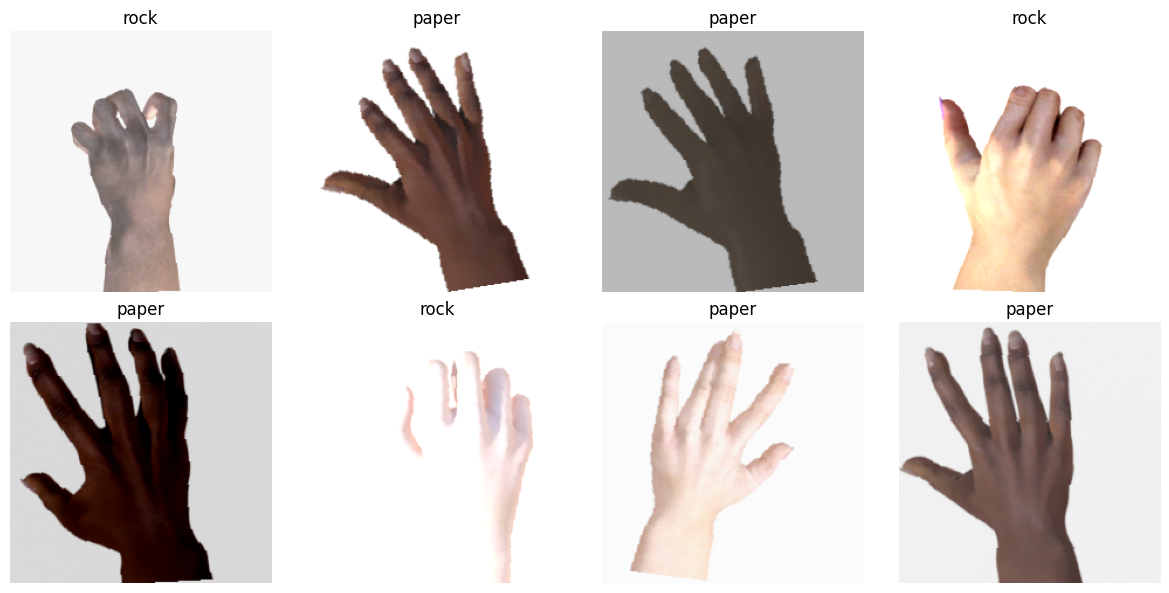

In [7]:
show_image(train_loader)

In [8]:
val_transform = transforms.Compose([transforms.Resize(256),
                                 transforms.CenterCrop(224),
                                 transforms.ToTensor(),
                                 transforms.Normalize(mean=[0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225])])

val_dataset = datasets.ImageFolder(val_path, val_transform)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size = 32, shuffle = False)

In [9]:
import torchvision.models as models

model = models.resnet18(weights = models.ResNet18_Weights.IMAGENET1K_V1)

In [10]:
# Замораживаем параметры слоя, чтобы они не обновлялись при обратном распространении ошибки
for param in model.parameters():
  param.requires_grad = False

model.fc = torch.nn.Linear(512, 3)

In [11]:
need_params = [param for param in model.parameters() if param.requires_grad]

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params = need_params, lr = 0.001)

In [12]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [13]:
def evaluate(model, loader):
  model.eval()
  running_loss = 0.0
  correct = 0
  total = 0

  with torch.no_grad():
    for images, labels in loader:
      images = images.to(device)
      labels = labels.to(device)

      outputs = model(images)
      loss = criterion(outputs, labels)

      running_loss += loss.item() * images.size(0)
      preds = outputs.argmax(dim=1)
      correct += (preds == labels).sum().item()
      total += labels.size(0)

  loss = running_loss / total
  acc = correct / total

  return loss, acc


In [14]:
num_epochs = 15

# списки для графиков
train_losses, train_accs = [], []
val_losses, val_accs = [], []

for epoch in range(num_epochs):
  model.train()
  running_loss = 0.0
  correct = 0
  total = 0

  for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)

    outputs = model(images)
    loss = criterion(outputs, labels)

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()

    running_loss += loss.item() * images.size(0)   # суммарная ошибка по всем картинкам
    preds = outputs.argmax(dim=1)                  # номер класса с максимальным числом
    correct += (preds == labels).sum().item()      # сколько угадали в этом батче
    total += labels.size(0)                        # сколько картинок было

  train_loss = running_loss / total
  train_acc = correct / total                                    # доля правильных
  # print(f'Эпоха {epoch+1}: loss={train_loss:.3f}, acc={train_acc:.3f}')

  # validation
  val_loss, val_acc = evaluate(model, val_loader)

  train_losses.append(train_loss)
  train_accs.append(train_acc)
  val_losses.append(val_loss)
  val_accs.append(val_acc)

  print(f'Эпоха {epoch+1}: train loss={train_loss:.3f}, acc={train_acc:.3f} |' f'val loss={val_loss:.3f}, acc={val_acc:.3f}')

Эпоха 1: train loss=0.690, acc=0.747 |val loss=0.625, acc=0.726
Эпоха 2: train loss=0.313, acc=0.937 |val loss=0.487, acc=0.809
Эпоха 3: train loss=0.221, acc=0.958 |val loss=0.384, acc=0.860
Эпоха 4: train loss=0.179, acc=0.965 |val loss=0.413, acc=0.828
Эпоха 5: train loss=0.169, acc=0.957 |val loss=0.344, acc=0.858
Эпоха 6: train loss=0.131, acc=0.971 |val loss=0.319, acc=0.858
Эпоха 7: train loss=0.118, acc=0.977 |val loss=0.370, acc=0.841
Эпоха 8: train loss=0.109, acc=0.976 |val loss=0.389, acc=0.836
Эпоха 9: train loss=0.108, acc=0.971 |val loss=0.368, acc=0.839
Эпоха 10: train loss=0.102, acc=0.975 |val loss=0.287, acc=0.871
Эпоха 11: train loss=0.091, acc=0.979 |val loss=0.465, acc=0.790
Эпоха 12: train loss=0.097, acc=0.977 |val loss=0.348, acc=0.852
Эпоха 13: train loss=0.080, acc=0.978 |val loss=0.338, acc=0.855
Эпоха 14: train loss=0.082, acc=0.979 |val loss=0.396, acc=0.815
Эпоха 15: train loss=0.072, acc=0.978 |val loss=0.428, acc=0.815


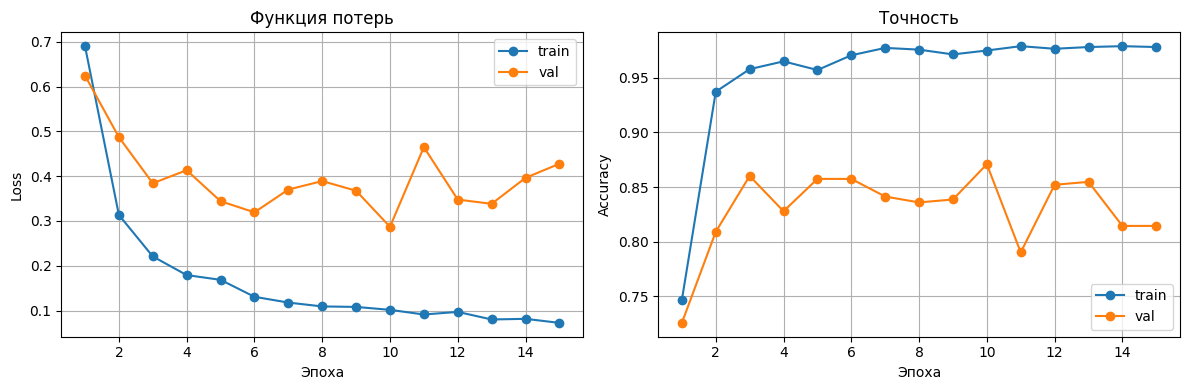

In [15]:
epochs = range(1, len(train_losses) + 1)   # номера эпох для оси X: 1, 2, 3...

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))   # два графика рядом

# loss
ax1.plot(epochs, train_losses, marker='o', label='train')
ax1.plot(epochs, val_losses, marker='o', label='val')
ax1.set_xlabel('Эпоха')
ax1.set_ylabel('Loss')
ax1.set_title('Функция потерь')
ax1.legend()
ax1.grid(True)

# accuracy
ax2.plot(epochs, train_accs, marker='o', label='train')
ax2.plot(epochs, val_accs, marker='o', label='val')
ax2.set_xlabel('Эпоха')
ax2.set_ylabel('Accuracy')
ax2.set_title('Точность')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

Явного переобучения нет: val loss не начал устойчиво расти. Но после 8 эпох модель почти перестала становиться лучше на новых данных, а на train продолжает улучшаться. Это начало переобучения: дальнейшие эпохи мало что дают.

In [16]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
test_hard_path = '/content/drive/MyDrive/cv_test_photos/test_hard'
test_easy_path = '/content/drive/MyDrive/cv_test_photos/test_easy'

In [18]:
test_hard_dataset = datasets.ImageFolder(test_hard_path, transform=val_transform)
test_easy_dataset = datasets.ImageFolder(test_easy_path, transform=val_transform)

test_hard_loader = torch.utils.data.DataLoader(test_hard_dataset, batch_size=32)
test_easy_loader = torch.utils.data.DataLoader(test_easy_dataset, batch_size=32)

In [19]:
print(train_dataset.classes)
print(test_hard_dataset.classes)

['paper', 'rock', 'scissors']
['paper', 'rock', 'scissors']


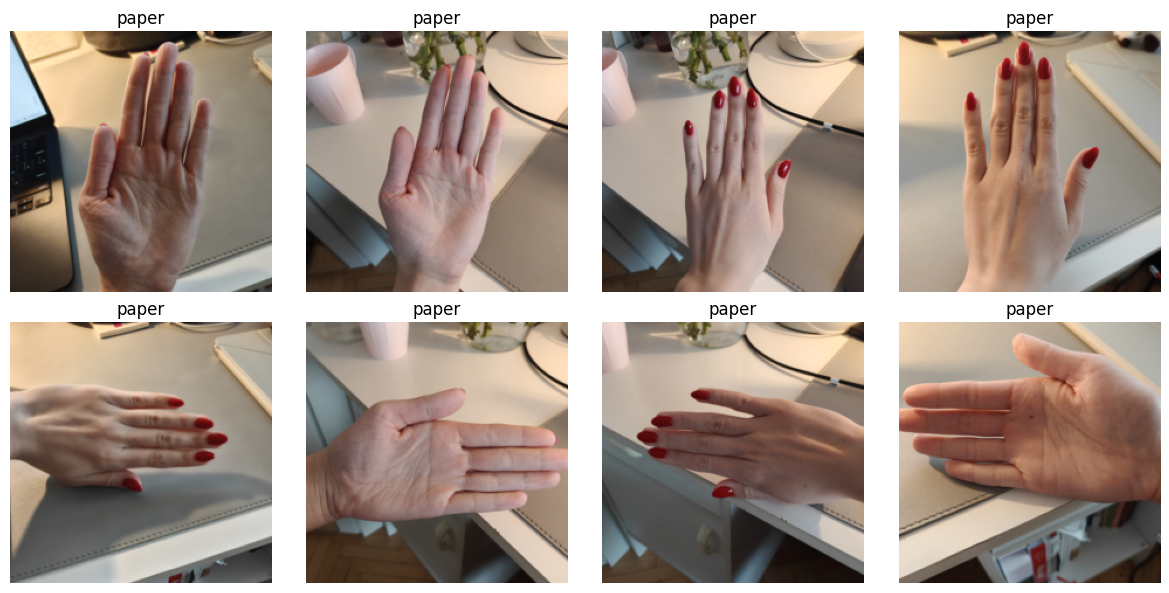

In [20]:
show_image(test_hard_loader)

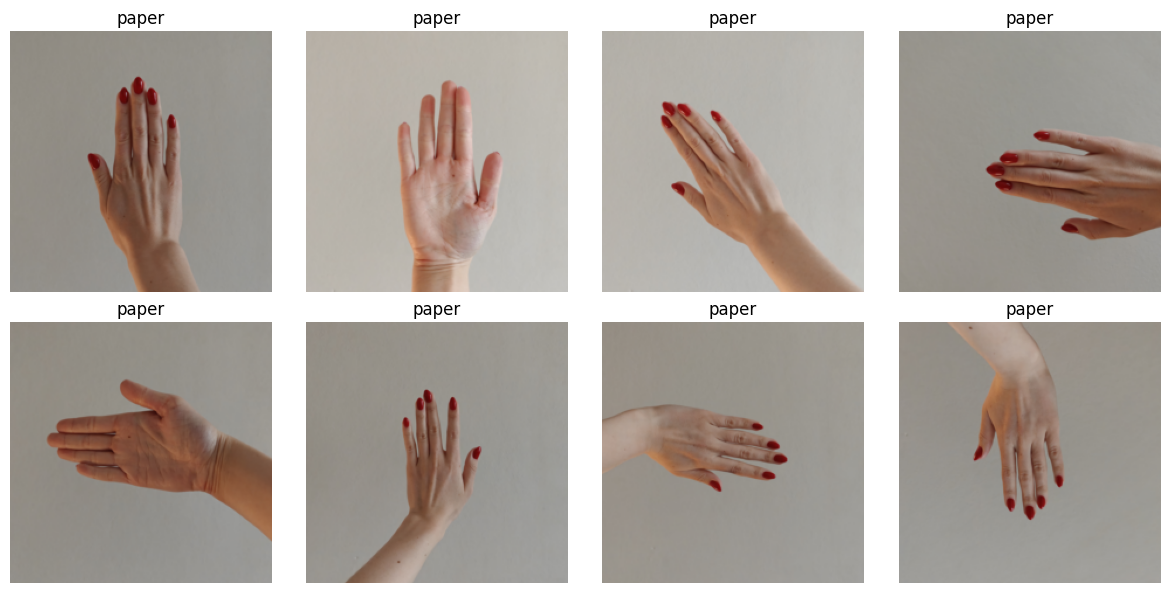

In [21]:
show_image(test_easy_loader)

In [22]:
# test
test_easy_loss, test_easy_acc = evaluate(model, test_easy_loader)
test_hasrd_loss, test_hard_acc = evaluate(model, test_hard_loader)

print(f'test_easy_loss = {test_easy_loss} | test_easy_acc = {test_easy_acc}')
print(f'test_hasrd_loss = {test_hasrd_loss} | test_hard_acc = {test_hard_acc}')

test_easy_loss = 1.1073554754257202 | test_easy_acc = 0.6333333333333333
test_hasrd_loss = 1.9987303018569946 | test_hard_acc = 0.3870967741935484


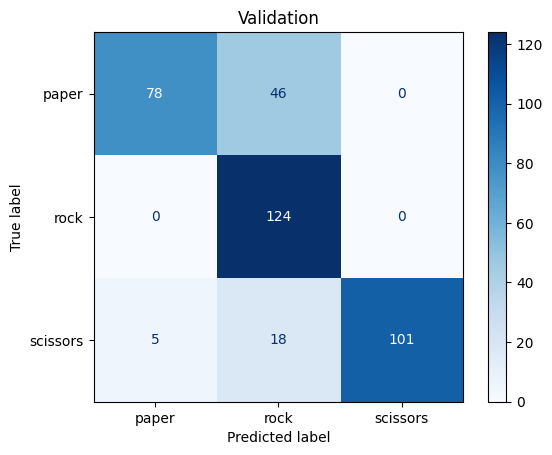

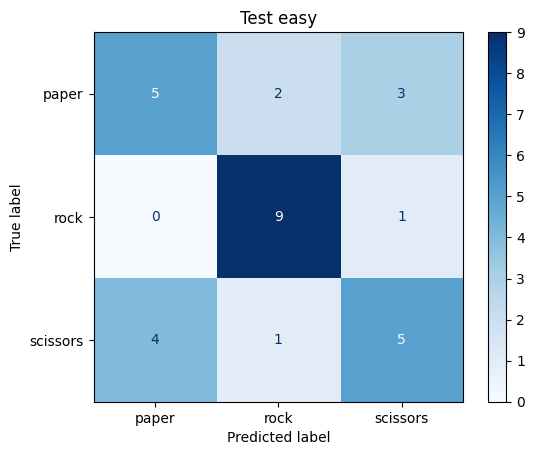

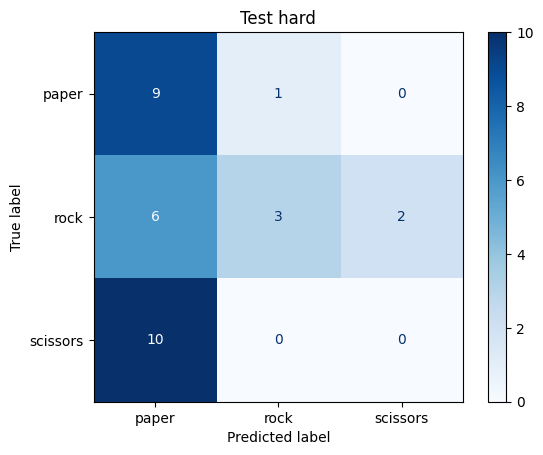

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusion(model, loader, title):
  model.eval()
  all_preds, all_labels = [], []          # сюда собираем ответы модели и правильные метки

  with torch.no_grad():
    for images, labels in loader:
      images = images.to(device)
      outputs = model(images)
      preds = outputs.argmax(dim=1)
      all_preds.extend(preds.cpu().tolist())    # с GPU на процессор, потом в обычный список
      all_labels.extend(labels.tolist())        # labels остались на CPU, переносить не нужно

  cm = confusion_matrix(all_labels, all_preds)  # строки: правильный класс, столбцы: ответ модели
  disp = ConfusionMatrixDisplay(cm, display_labels=train_dataset.classes)
  disp.plot(cmap='Blues')
  plt.title(title)
  plt.show()

plot_confusion(model, val_loader, 'Validation')
plot_confusion(model, test_easy_loader, 'Test easy')
plot_confusion(model, test_hard_loader, 'Test hard')